In [1]:
import sys
print("Curso de Algebra Lineal con Python")
print(f"La version de Python es {sys.version}")

Curso de Algebra Lineal con Python
La version de Python es 3.13.15 (main, Aug  6 2026, 11:06:23) [GCC 11.4.0]


### Documentacion

https://numpy.org/doc/stable/user/absolute_beginners.html

https://matplotlib.org/stable/tutorials/pyplot.html

In [2]:
import numpy as np

#creacion de array de datos, similar a una lista pero mas eficiente
datos = np.array([1, 2, 3, 4, 5, 6])

print(datos)
print(datos.shape)   #tupla que devuelta la cantidad de elementos del vector
# Util para asegurarnos de saber la forma de nuestros datos ya que en ML necesitamos saber la forma de nuestros datos
# Para modelar o entrenar

[1 2 3 4 5 6]
(6,)


In [3]:
x = np.array([1,2,3,4,5,6])
y = np.array([4,3,2,6,8,9])

vec1 = ([4,5])

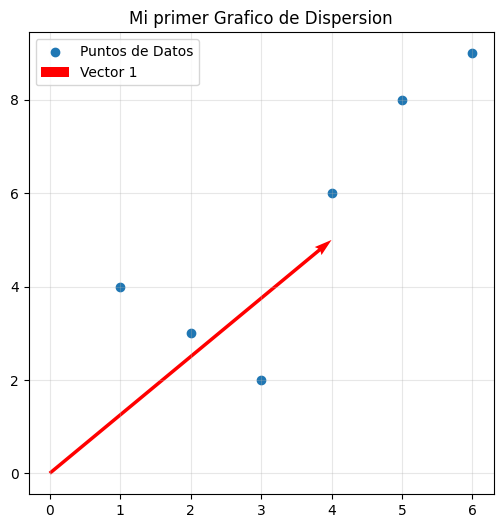

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))   # creamos Lienzo

#Grafico de Dispersion
plt.scatter(x,y, label="Puntos de Datos")

#Primer coordenada, origen de la flecha
plt.quiver(0,0, vec1[0], vec1[1], angles="xy", scale_units="xy", scale=1, color="red", label="Vector 1")

plt.title("Mi primer Grafico de Dispersion")
plt.legend()  #Para compilar todas las etiquetas
plt.grid(True, alpha=0.3)    #Grilla que se mostrara en el grafico
plt.show()

## Escalar

In [5]:
# precio, calificacion

producto_a = np.array([20.0, 4.5])

print(f"Vector Producto: {producto_a}")

Vector Producto: [20.   4.5]


In [6]:
print(f"Numero de ejes o dimension del producto {producto_a.ndim}")

print(f"Forma del producto {producto_a.shape}")

print(f"Numero total de elementos del producto {producto_a.size}")

Numero de ejes o dimension del producto 1
Forma del producto (2,)
Numero total de elementos del producto 2


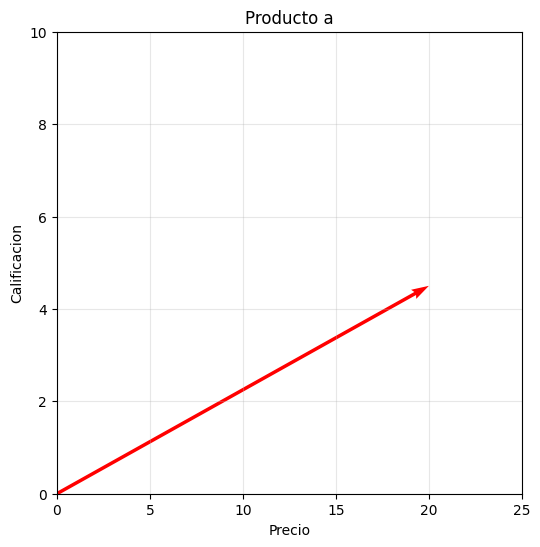

In [7]:
plt.figure(figsize=(6,6))

plt.quiver(0,0, producto_a[0], producto_a[1], angles="xy", scale_units="xy", scale=1, color="red")

plt.title("Producto a")
plt.xlabel("Precio")
plt.ylabel("Calificacion")
plt.xlim(0, 25)
plt.ylim(0, 10)
plt.grid(True, alpha=0.3)
plt.show()

### Matrices

- Las filas son observaciones, lo que contiene la columna, un punto de datos
- Las columnas son caracteristicas, atributos, edad, precio, etc

In [8]:
# Ejemplo Matriz NETFLIX 4 peliculas (filas usuarios, columna puntuacion)
puntuacion = np.array([
    [5,1,2,0],
    [3,1,2,0],
    [2,1,2,4],
    [4,1,2,5],
])

print(puntuacion)

[[5 1 2 0]
 [3 1 2 0]
 [2 1 2 4]
 [4 1 2 5]]


In [9]:
#Inspeccionamos la matriz

print(puntuacion.ndim)   #Dimension
print(puntuacion.shape)  # 4 filas y 4 column
print(puntuacion.size)   # cant elementos de la matriz

2
(4, 4)
16


In [10]:
calificacion_pedro = puntuacion[0]
print(calificacion_pedro)

[5 1 2 0]


In [11]:
calificaciones_pelicula3 = puntuacion[:, 2]   #todas las filas de la matriz con la columna 3
print(calificaciones_pelicula3)

[2 2 2 2]


### Tensor
- Generalizacion de una matriz de mas de 2 dimensiones

In [12]:
#RGB y/o pixeles
imagen_tensor = np.array([
    [
        [255, 0, 0],
        [0, 255, 0],
        [0, 0, 255],
    ],
    [
        [255, 125, 100],
        [200, 255, 40],
        [115, 0, 255],
    ]
])

In [13]:
#Inspeccionamos El Tensor

print(imagen_tensor.ndim)   # 3 dimensiones
print(imagen_tensor.shape)  # 2 matrices de 3 filas, 3 columnas
print(imagen_tensor.size)   # cant elementos de la matriz

3
(2, 3, 3)
18


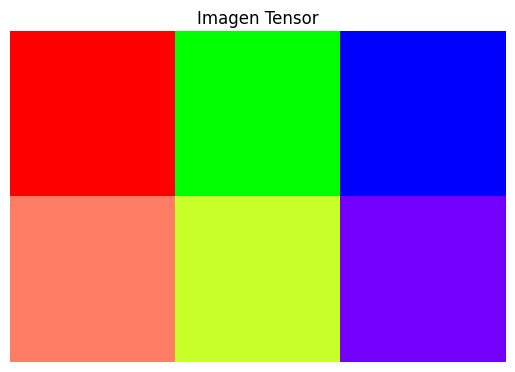

In [14]:
plt.imshow(imagen_tensor)
plt.title("Imagen Tensor")
plt.axis("off")
plt.show()

### Errores

Aprender a operar vectores y matrices con NumPy es clave para entender cómo un modelo de machine learning mide errores, se corrige y acumula información. Aquí verás cómo aplicar resta, multiplicación por escalar, suma de matrices y broadcasting con ejemplos prácticos en Python, pensados para quienes están empezando con ciencia de datos.

- ¿Cómo se mide el error de un modelo con resta de vectores?

Un sistema de recomendación aprende comparando lo que predice con lo que realmente te gusta. Esa diferencia es el error, y se obtiene restando dos vectores

In [15]:
calificaciones_reales = np.array([5, 2])

prediccion_modelo = np.array([4, 4])

print(calificaciones_reales)
print(prediccion_modelo)

[5 2]
[4 4]


In [16]:
error = calificaciones_reales - prediccion_modelo

print(error)

[ 1 -2]


### ¿Por qué multiplicar el error por un escalar pequeño?

Un modelo no corrige todo su conocimiento de golpe porque sería inestable. En su lugar, multiplica el vector de error por un número pequeño para dar un paso suave en la dirección correcta.

Ese número se llama tasa de aprendizaje o learning rate, y controla el tamaño del ajuste. Usar 0.1 equivale a corregir solo el 10% del error, lo que permite que el modelo aprenda de forma estable sin reaccionar exageradamente.

In [17]:
#Este ciclo de calculo, ajuste, resta es la base de como los modelos entrenan y mejoran
porcentaje_ajuste = 0.1

ajuste = error * porcentaje_ajuste

print(ajuste)

[ 0.1 -0.2]


### Tipos de Suma

- Sumar 2 matrices de la misma forma

- Sumar un vector a una matriz completa

In [18]:
ventas_enero = np.array([
    [150, 200, 180],
    [120, 90, 100]
])

ventas_febrero = np.array([
    [130, 210, 190],
    [110, 80, 120]
])

print(ventas_enero)
print(ventas_febrero)

[[150 200 180]
 [120  90 100]]
[[130 210 190]
 [110  80 120]]


In [19]:
#Suma de matrices
ventas_totales = ventas_enero + ventas_febrero

print(ventas_totales)

[[280 410 370]
 [230 170 220]]


### Broadcasting: Eficiencia y Ajustes Globales

- Sumar una matriz con un vector ("algo matematicamente imposible")

In [20]:
bonificaciones = np.array([10, 15, 5])

print(ventas_enero.shape)
print(bonificaciones.shape)

(2, 3)
(3,)


In [21]:
#Numpy expande virtualmente el array mas pequeno con el mas grande
# Para que su forma coincida con el mas grande y asi poder sumar
# [10, 15 , 5]
# [10, 15 , 5]
ventas_con_bono = ventas_enero + bonificaciones

print(ventas_con_bono)

[[160 215 185]
 [130 105 105]]


En el ejemplo anterior, la matriz tiene 3 columnas y el vector tiene 3 elementos, así que cumple la condición. Pero si el vector tuviera 4 elementos en lugar de 3, NumPy lanzaría un error

### Norma L2 o Euclidiana y L1 con Numpy

Las normas de vectores son la forma más clara y práctica de medir la intensidad, longitud y distancia en datos. En machine learning ayudan a comparar perfiles, controlar modelos con regularización y estandarizar vectores para analizar solo su dirección. Aquí verás la norma L2, su interpretación con el teorema de Pitágoras, y cómo calcular L1 (utilizado para outliers), L0 y L∞ con NumPy.

In [22]:
# L2 La mas utilizada

perfil_ana = np.array([5, 1])  # ciencia ficción = 5, comedia = 1
perfil_juan = np.array([1, 5])  # ciencia ficción = 1, comedia = 5

norma_ana = np.linalg.norm(perfil_ana)   #linalg (linear algebra) y norm (norma)
norma_juan = np.linalg.norm(perfil_juan)

print(f"norma de ana: {norma_ana:.2f}")
print(f"norma de juan: {norma_juan:.2f}")

norma de ana: 5.10
norma de juan: 5.10


In [23]:
vector = np.array([3, -4, 0])

norma_L1 = np.linalg.norm(vector, ord=1)
print(f"norma L1 del vector: {norma_L1}")

norma L1 del vector: 7.0


In [24]:
norma_L0 = np.count_nonzero(vector)
print(f"norma L0 del vector: {norma_L0}")

norma L0 del vector: 2


In [25]:
norma_Linf = np.linalg.norm(vector, ord=np.inf)
print(f"norma L infinito del vector: {norma_Linf}")

norma L infinito del vector: 4.0


### El producto punto esta detrás de:
- Sistema de recomendación
- Busqueda semántica
- Modelos del lenguaje

La norma de un vector te dice su longitud, pero no su dirección. Y en IA, la dirección lo es todo: revela si dos vectores apuntan hacia los mismos intereses, significados o categorías.

Regla: Los 2 vectores deben tener la misma cantidad de componentes

https://www.myscale.com/blog/mastering-data-science-cosine-similarity-vs-dot-product-insights/

In [26]:
vect = np.array([2, 3])
vect2 = np.array([4, 1])

producto_punto_np = np.dot(vect, vect2)
print(f"Resultado con no.dot(): {producto_punto_np}")

# FORMA MAS RECOMENDABLE Y ACTUALIZADA

producto_punto_actual = vect @ vect2
print(f"Resultado con @: {producto_punto_actual}")

Resultado con no.dot(): 11
Resultado con @: 11


###Interpretamos los resultados

- Cerca a 1: Vectores muy similares (0°)
- Cercano a 0: no tiene relacion lineal (90°)
- Cercano a -1: direcciones opuestas (180°)

In [27]:
!pip install gensim  #libreria para procesamiento de lenguaje natural

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 37.6 MB/s eta 0:00:00


In [28]:
import gensim.downloader as api

print("Descargando modelo de vectores de palabras...")

word_vectors = api.load("glove-wiki-gigaword-50")

print("Listo: Modelo cargado")

Descargando modelo de vectores de palabras...
[==================================================] 100.0% 66.0/66.0MB downloaded
Listo: Modelo cargado


In [29]:
rey = word_vectors["king"]
hombre = word_vectors["man"]
reina = word_vectors["queen"]
gato = word_vectors["cat"]

In [30]:
def similitud_coseno(v1, v2):
  return np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2))

In [31]:
#similitud entre rey y hombre
sim_rey_hombre = similitud_coseno(rey, hombre)

#similitud entre rey y reina
sim_rey_reina = similitud_coseno(rey, reina)

#similitud entre rey y gato
sim_rey_gato = similitud_coseno(rey, gato)

In [32]:
print(f"Similitud entre Rey y Hombre: {sim_rey_hombre:.2f}")
print(f"Similitud entre Rey y Reina: {sim_rey_reina:.2f}")
print(f"Similitud entre Rey y Gato: {sim_rey_gato:.2f}")

Similitud entre Rey y Hombre: 0.53
Similitud entre Rey y Reina: 0.78
Similitud entre Rey y Gato: 0.39


### Multiplicacion de Matrices